## 3. 딥러닝 기초 및 GPU 가속

> 전체 노트북 파일에서 과제 범위에 해당되는 코드 셀과 참고용 마크다운 셀을 가져와 포함했습니다.

포함된 내용
- GPU 가속 (잔상효과, Convolution2D)
- MNIST 데이터셋 main_gpu() 함수
- CIFAR-10 데이터셋 모델 학습 파트

### import문 및 함수 선언

In [1]:
import time
import random

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# CuPy를 torch보다 먼저 import하면 다른 버전의 cuBLAS가 로드되어 학습 중 CUBLAS_STATUS_INVALID_VALUE 에러가 발생함
import cupy as cp

In [2]:
def relu(x):
    return np.maximum(0, x)

In [3]:
def convolution2d(image, kernel, bias=0.0, stride=1, padding=0):
    """
    2차원 이미지에 하나의 CNN 필터를 적용.

    Parameters
    ----------
    image : np.ndarray
        입력 이미지, shape = (height, width)
    kernel : np.ndarray
        CNN 필터, shape = (kernel_height, kernel_width)
    bias : float
        필터 출력에 더할 편향
    stride : int
        필터가 이동하는 간격
    padding : int
        입력 이미지 가장자리에 추가할 픽셀의 개수

    Returns
    -------
    output : np.ndarray
        편향까지 적용된 convolution 결과
    """

    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    # 이미지 가장자리에 zero padding 적용
    padded_image = np.pad(
        image,
        ((padding, padding), (padding, padding)),
        mode="constant",
        constant_values=0
    )

    # (H, W: 입력 이미지 높이 및 너비, P: Padding 픽셀 값, S: Stride 픽셀 값)
    # Convolution 출력 이미지 높이 = floor((H + 2P - K) / S) + 1
    output_height = (padded_image.shape[0] - kernel_height) // stride + 1

    # Convolution 출력 이미지 너비 = floor((W + 2P - K) / S) + 1
    output_width = (padded_image.shape[1] - kernel_width) // stride + 1

    # 계산한 크기로 출력 이미지 준비
    output = np.zeros((output_height, output_width), dtype=np.float32)

    # 커널을 움직이며 필터 적용
    for output_y in range(output_height):
        for output_x in range(output_width):
            # 커널을 적용할 이미지 영역의 좌측상단
            start_y = output_y * stride
            start_x = output_x * stride

            # 커널을 적용할 이미지 영역을 crop
            image_region = padded_image[
                start_y:start_y + kernel_height,
                start_x:start_x + kernel_width
            ]

            # 필터를 적용하여 가중합 계산
            weighted_sum = np.sum(image_region * kernel)

            # 편향 적용
            output[output_y, output_x] = weighted_sum + bias

    return output

In [4]:
# x축 방향 edge (세로 선) 검출 필터
dx_edge_filter = np.array(
    [
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ],
    dtype=np.float32
)

# y축 방향 edge (가로 선) 검출 필터
dy_edge_filter = np.array(
    [
        [-1, -1, -1],
        [0, 0, 0],
        [1, 1, 1]
    ],
    dtype=np.float32
)

In [5]:
# 너무 약한 특징 (0.2 이하)은 무시
dx_bias = -0.2
dy_bias = -0.2

### G. GPU 병렬 연산 (CuPy)

#### $4)$ CuPy를 활용한 배열 연산 GPU 가속 1 – 이미지 잔상 효과 구현

`CuPy`를 사용하여 대규모 배열 연산이 GPU에서 어떻게 가속되는지 알아보겠습니다.

이번 실습에서는 이미지 배열을 여러 픽셀만큼 이동한 뒤, 각 이미지에 서로 다른 가중치를 곱하여 누적하는 이미지 잔상(Image Trail) 효과를 구현합니다.

#### 이미지 잔상 효과의 원리

원본 이미지를 오른쪽으로 조금씩 이동한 복사본들을 만들고, 각 복사본에 가중치를 곱한 뒤 모두 더합니다.

```text
원본 이미지 × weight[0]
오른쪽으로 1픽셀 이동한 이미지 × weight[1]
오른쪽으로 2픽셀 이동한 이미지 × weight[2]
오른쪽으로 3픽셀 이동한 이미지 × weight[3]
...
```

가중치는 이동 거리가 멀어질수록 작아지도록 설정합니다. 따라서 원본 이미지에 가까운 잔상은 선명하게 나타나고, 멀리 떨어진 잔상은 점점 흐리게 나타납니다.

예를 들어 입력 배열과 가중치가 다음과 같다고 가정합니다.

```text
입력 배열:  [10, 20, 30, 40, 50]
가중치:     [0.6, 0.3, 0.1]
```

각 이동 결과에 가중치를 곱하면 다음과 같습니다.

```text
이동 없음:      [10, 20, 30, 40, 50] × 0.6
오른쪽 1칸:     [ 0, 10, 20, 30, 40] × 0.3
오른쪽 2칸:     [ 0,  0, 10, 20, 30] × 0.1
```

이 결과들을 같은 위치끼리 더하면 오른쪽 방향으로 이어지는 잔상 효과가 만들어집니다.

#### CPU와 GPU의 처리 방식

NumPy를 사용하는 CPU 코드에서는 출력 이미지의 픽셀을 하나씩 순차적으로 계산합니다.

반면 CuPy를 사용하는 GPU 코드에서는 이동 횟수를 순차적으로 반복하되, 각 반복에서 이미지 배열 전체에 대한 곱셈과 덧셈을 GPU에서 병렬로 처리합니다.

* CPU
  * 출력 픽셀을 하나씩 순차적으로 계산
* GPU
  * 이동 횟수는 순차적으로 반복
  * 각 이동 단계의 전체 픽셀 연산은 병렬로 처리

**글로벌 변수 정의:**

In [6]:
IMAGE_PATH = "../src/images/seagull.jpg"

TARGET_WIDTH = 1280
TARGET_HEIGHT = 720

TRAIL_LENGTH = 32

**이미지 불러오기:**

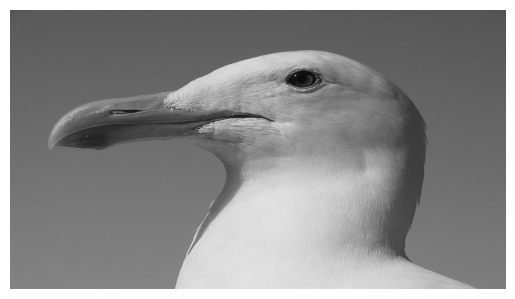

In [7]:
img_gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)

if img_gray is None:
    raise FileNotFoundError(f"이미지를 읽을 수 없습니다: {IMAGE_PATH}")

img_gray = cv2.resize(
    img_gray,
    (TARGET_WIDTH, TARGET_HEIGHT),
    interpolation=cv2.INTER_AREA
)

input_np = img_gray.astype(np.float32) / 255.0

plt.imshow(input_np, cmap="gray")
plt.axis("off");

**잔상 효과 함수 (CPU):**

In [8]:
# TODO: NumPy를 사용하여 잔상 효과 함수 정의

def motion_trail_np(image, weights):
    """
    NumPy를 이용해 이미지 잔상 효과를 생성한다.

    출력 픽셀을 Python 반복문으로 하나씩 계산한다.
    """

    # TODO: 필요한 변수 정의 및 출력 배열 생성
    image_height, image_width = image.shape
    output = np.zeros((image_height, image_width), dtype=np.float32)

    for output_y in range(image_height):
        for output_x in range(image_width):
            total_value = 0.0 # 누적 총합 변수 초기화

            for shift in range(TRAIL_LENGTH):
                # TODO: x값 shift
                input_x = output_x - shift
                if input_x < 0: # 이미지 왼쪽 끝 인덱스 넘침 처리
                    continue

                # TODO: shift한 픽셀을 누적
                pixel_value = image[output_y, input_x] # y좌표가 먼저 와야함
                weight = weights[shift]

                total_value += pixel_value * weight
                
            # TODO: 출력 배열에 누적 픽셀 저장
            output[output_y, output_x] = total_value

    return output

**잔상 효과 함수 (GPU):**

In [9]:
# TODO: CuPy를 사용하여 잔상 효과 함수 정의

def motion_trail_cp(image, weights):
    """
    CuPy를 이용해 이미지 잔상 효과를 생성한다.

    이동 거리는 Python에서 순차적으로 반복하지만,
    각 이동 거리의 이미지 전체 계산은 GPU에서 병렬 처리한다.
    """

    # TODO: 필요한 변수 정의 및 출력 배열 생성
    image_height, image_width = image.shape
    output = cp.zeros((image_height, image_width), dtype=cp.float32)

    for shift in range(len(weights)):
        # TODO: 배열 slicing
        input_region = image[:, 0:image_width - shift] # 전체 너비에서 shift만큼 뺀 범위가 입력(잔상을 가져올 곳)
        output_region = output[:, shift:image_width] # shift부터 전체 너비 끝까지 간 범위가 출력 범위(잔상 영향 범위)
        # 가로측 잔상에 대해서만 연산하므로 앞쪽 인덱스(높이)는 전체 범위(:) 처리함
        
        # TODO: GPU가 병렬 연산할 output_region 계산 코드
        output_region += input_region * weights[shift] # 출력 영역에 입력 영역 * 가중치를 더함

    return output

**가중치 설정:**

In [10]:
# 이동 거리가 멀어질수록 가중치를 작게 설정
weights_np = np.linspace( 
    1.0,
    0.05,
    TRAIL_LENGTH,
    dtype=np.float32
)

# 전체 가중치의 합을 1로 정규화
weights_np /= np.sum(weights_np)

**NumPy CPU 처리:**

In [11]:
cpu_start = time.perf_counter()

output_np = motion_trail_np(
    image=input_np,
    weights=weights_np
)

cpu_end = time.perf_counter()

cpu_time = cpu_end - cpu_start

**CuPy 배열 준비:**

In [12]:
# TODO: NumPy 배열을 CuPy 배열로 변환

upload_start = time.perf_counter()

input_cp = cp.asarray(input_np)
weights_cp = cp.asarray(weights_np)

cp.cuda.Stream.null.synchronize()

upload_end = time.perf_counter()

upload_time = upload_end - upload_start

**GPU 워밍업:**

In [13]:
warmup_image = cp.zeros((64, 64), dtype=cp.float32)
warmup_weights = cp.asarray(weights_np[:4])

_ = motion_trail_cp(
    image=warmup_image,
    weights=warmup_weights
)

cp.cuda.Stream.null.synchronize()

**CuPy GPU 처리:**

In [14]:
cp.cuda.Stream.null.synchronize()

gpu_start = time.perf_counter()

output_cp = motion_trail_cp(
    image=input_cp,
    weights=weights_cp
)

cp.cuda.Stream.null.synchronize()

gpu_end = time.perf_counter()

gpu_time = gpu_end - gpu_start

**GPU 결과를 CPU로 가져오기:**

In [15]:
# TODO: output_cp를 CPU 메모리로 복사

download_start = time.perf_counter()

output_cp_np = cp.asnumpy(output_cp)

download_end = time.perf_counter()

download_time = download_end - download_start

**결과 비교:**

In [16]:
compute_speedup = cpu_time / gpu_time

gpu_total_time = upload_time + gpu_time + download_time
total_speedup = cpu_time / gpu_total_time

**결과 출력:**

In [17]:
print("========== NumPy CPU ==========")
print(f"Processing time: {cpu_time:.4f} seconds")
print()

print("========== CuPy GPU ==========")
print(f"CPU to GPU: {upload_time:.4f} seconds")
print(f"GPU processing: {gpu_time:.4f} seconds")
print(f"GPU to CPU: {download_time:.4f} seconds")
print(f"Total GPU time: {gpu_total_time:.4f} seconds")
print()

print("========== Comparison ==========")
print(f"Compute-only speedup: {compute_speedup:.2f}x")
print(f"Including transfers: {total_speedup:.2f}x")

========== NumPy CPU ==========
Processing time: 4.7332 seconds

========== CuPy GPU ==========
CPU to GPU: 0.0790 seconds
GPU processing: 0.0021 seconds
GPU to CPU: 0.0007 seconds
Total GPU time: 0.0818 seconds

========== Comparison ==========
Compute-only speedup: 2236.77x
Including transfers: 57.84x


**이미지 출력:**

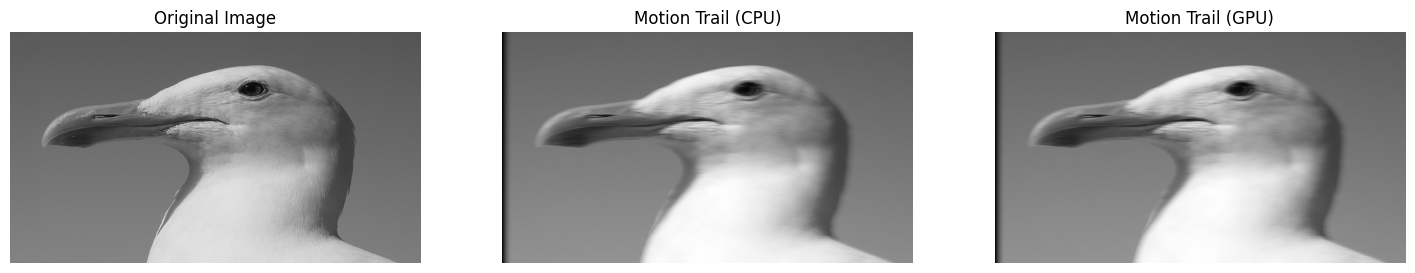

In [18]:
plt.figure(figsize=(18,12))

plt.subplot(1,3,1), plt.imshow(input_np, cmap="gray"), plt.title("Original Image")
plt.subplot(1,3,2), plt.imshow(output_np, cmap="gray"), plt.title("Motion Trail (CPU)")
plt.subplot(1,3,3), plt.imshow(output_cp_np, cmap="gray"), plt.title("Motion Trail (GPU)")

for ax in plt.gcf().axes:
    ax.axis("off")

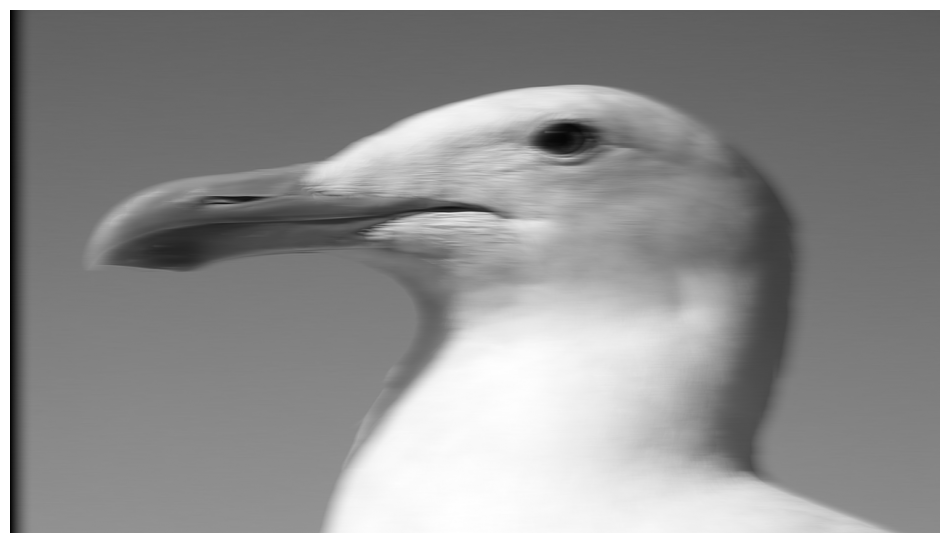

In [19]:
plt.figure(figsize=(12,8))
plt.imshow(output_cp_np, cmap="gray")
plt.axis("off");

#### $5)$ CuPy를 활용한 배열 연산 GPU 가속 2 – Convolution 연산

이전 실습에서는 이미지 배열을 여러 픽셀만큼 이동하고, 각 배열에 서로 다른 가중치를 곱한 뒤 출력 배열에 누적하여 이미지 잔상 효과를 구현했습니다.

이 과정에서 이동 거리를 제어하는 for문은 Python에서 순차적으로 실행되지만, 각 반복에서 수행되는 이미지 배열 전체의 곱셈과 덧셈은 GPU에서 병렬로 처리된다는 점을 확인했습니다.

이번 실습에서는 이러한 배열 이동과 가중치 누적 방식을 2차원으로 확장하여 convolution 연산을 구현합니다.

이전에 정의한 `convolution2d()` 함수는 NumPy를 사용하여 출력 이미지의 픽셀을 하나씩 순차적으로 계산합니다.

각 출력 위치에서 커널 크기만큼 이미지 영역을 잘라낸 뒤, 이미지 영역과 커널을 원소별로 곱하고 그 결과를 모두 더하여 하나의 출력 픽셀을 생성합니다.

```text
출력 위치 하나 선택
→ 커널 크기의 이미지 영역 추출
→ 이미지 영역과 커널의 가중합 계산
→ 출력 픽셀 하나 저장
```

이 방식은 convolution의 원리를 직접 확인하기에는 적합하지만, 이미지의 높이와 너비만큼 Python 반복문을 실행해야 하므로 큰 이미지에서는 처리 시간이 오래 걸립니다.

<br>

이번에는 이전에 정의한 `convolution2d()` 함수와 동일한 결과를 계산하는 CuPy 기반의 `convolution2d_cp()` 함수를 작성합니다.

CuPy 버전에서는 출력 픽셀을 하나씩 반복하지 않고, 커널의 각 원소를 순차적으로 선택합니다. 그리고 모든 출력 위치에서 현재 커널 원소와 대응되는 입력 픽셀을 배열로 선택한 뒤, 해당 커널 가중치를 곱하여 출력 배열 전체에 누적합니다.

```text
커널 원소 하나 선택
→ 모든 출력 위치에서 대응되는 입력 픽셀 선택
→ 배열 전체에 현재 커널 가중치 적용
→ 출력 배열 전체에 누적
```

두 함수는 계산 순서가 다르지만, 최종적으로 각 출력 픽셀에는 이미지 영역과 커널의 동일한 가중합이 저장됩니다.

<br>

**함수의 입력으로는 이전 실습과 동일한 이미지를 사용합니다:**

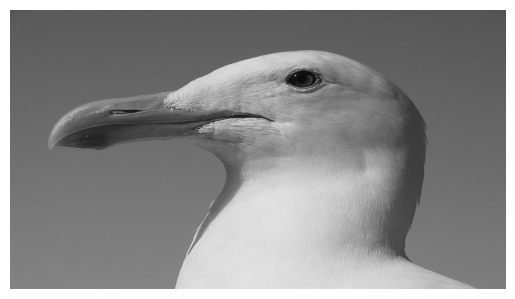

In [20]:
plt.imshow(input_np, cmap="gray")
plt.axis("off");

**Convolution 함수 정의 (CuPy):**

In [21]:
# TODO: CuPy를 사용하여 2차원 convolution 함수 정의

def convolution2d_cp(image, kernel, bias=0.0, stride=1, padding=0):
    """
    CuPy를 이용한 2차원 convolution.

    커널의 위치는 Python 반복문으로 순차 처리하고,
    각 위치에 해당하는 출력 배열 전체 연산은 GPU에서 처리한다.
    """

    kernel_height, kernel_width = kernel.shape

    padded_image = cp.pad(
        image,
        ((padding, padding), (padding, padding)),
        mode="constant",
        constant_values=0
    )

    output_height = (padded_image.shape[0] - kernel_height) // stride + 1
    output_width = (padded_image.shape[1] - kernel_width) // stride + 1

    output = cp.zeros((output_height, output_width), dtype=cp.float32)

    for kernel_y in range(kernel_height):
        for kernel_x in range(kernel_width):
            input_region = padded_image[
                kernel_y:kernel_y + output_height * stride:stride,
                kernel_x:kernel_x + output_width * stride:stride
            ]

            output += input_region * kernel[kernel_y, kernel_x]

    return output + bias

**NumPy CPU 처리:**

In [22]:
# TODO: 기존에 정의한 convolution2d 함수를 사용하여 convolution을 CPU로 처리
# TODO: 변수 재사용 가능

cpu_start = time.perf_counter()

output_dx_np = convolution2d(input_np, dx_edge_filter, bias=dx_bias, stride=1, padding=1)
output_dy_np = convolution2d(input_np, dy_edge_filter, bias=dy_bias, stride=1, padding=1)

cpu_time = time.perf_counter() - cpu_start

relu_dx_np = relu(output_dx_np)
relu_dy_np = relu(output_dy_np)

**CuPy GPU 처리:**

In [23]:
# TODO: convolution을 GPU로 처리 (변환-워밍업-처리 파이프라인 구현)
# TODO: 변수 재사용 가능

dx_edge_filter_cp = cp.asarray(dx_edge_filter)
dy_edge_filter_cp = cp.asarray(dy_edge_filter)

_ = convolution2d_cp(warmup_image, dx_edge_filter_cp, bias=dx_bias, stride=1, padding=1)
cp.cuda.Stream.null.synchronize()

gpu_start = time.perf_counter()

output_dx_cp = convolution2d_cp(input_cp, dx_edge_filter_cp, bias=dx_bias, stride=1, padding=1)
output_dy_cp = convolution2d_cp(input_cp, dy_edge_filter_cp, bias=dy_bias, stride=1, padding=1)

cp.cuda.Stream.null.synchronize()
gpu_time = time.perf_counter() - gpu_start

relu_dx_cp_np = cp.asnumpy(cp.maximum(output_dx_cp, 0))
relu_dy_cp_np = cp.asnumpy(cp.maximum(output_dy_cp, 0))

**결과 출력:**

In [24]:
# TODO: CPU/GPU 결과 비교 및 출력

max_difference = max(
    np.abs(relu_dx_np - relu_dx_cp_np).max(),
    np.abs(relu_dy_np - relu_dy_cp_np).max()
)

print("========== NumPy CPU ==========")
print(f"Processing time: {cpu_time:.4f} seconds")
print()

print("========== CuPy GPU ==========")
print(f"Processing time: {gpu_time:.4f} seconds")
print()

print("========== Comparison ==========")
print(f"Speedup: {cpu_time / gpu_time:.2f}x")
print(f"Max difference (CPU vs. GPU): {max_difference}")

========== NumPy CPU ==========
Processing time: 5.2487 seconds

========== CuPy GPU ==========
Processing time: 0.0021 seconds

========== Comparison ==========
Speedup: 2454.15x
Max difference (CPU vs. GPU): 2.384185791015625e-07


**이미지 출력:**

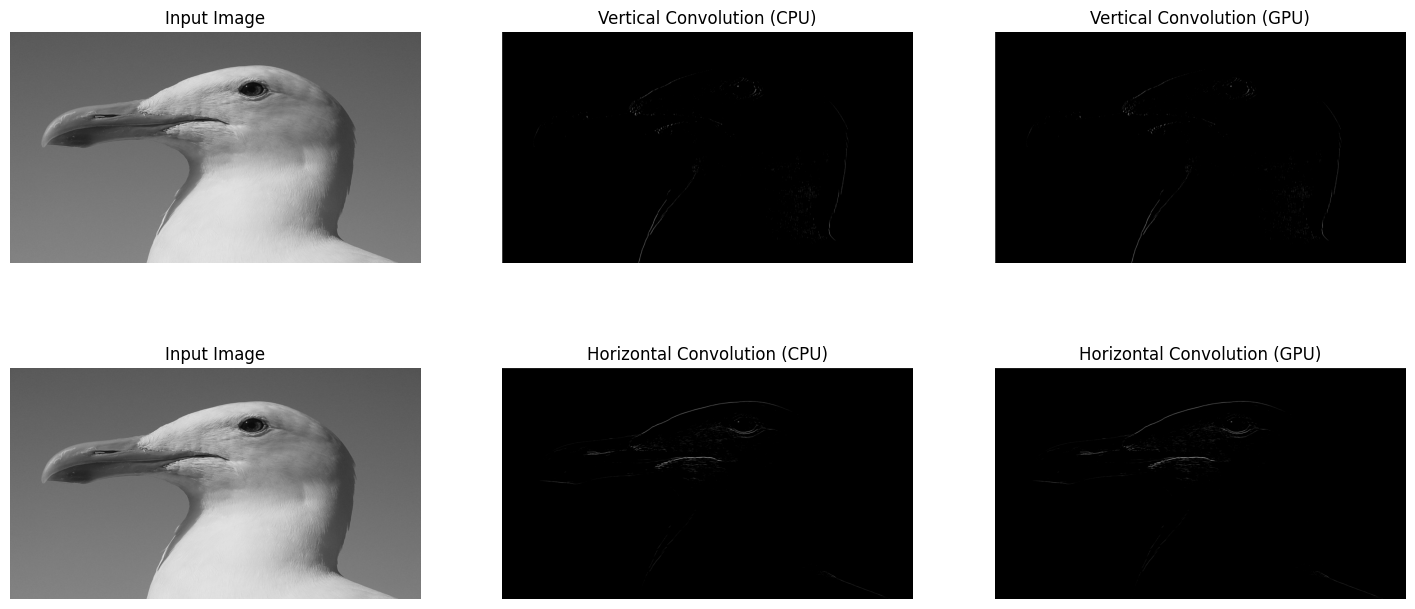

In [25]:
plt.figure(figsize=(18,8))

plt.subplot(2,3,1), plt.imshow(input_np, cmap="gray"), plt.title("Input Image")
plt.subplot(2,3,2), plt.imshow(relu_dx_np, cmap="gray"), plt.title("Vertical Convolution (CPU)")
plt.subplot(2,3,3), plt.imshow(relu_dx_cp_np, cmap="gray"), plt.title("Vertical Convolution (GPU)")
plt.subplot(2,3,4), plt.imshow(input_np, cmap="gray"), plt.title("Input Image")
plt.subplot(2,3,5), plt.imshow(relu_dy_np, cmap="gray"), plt.title("Horizontal Convolution (CPU)")
plt.subplot(2,3,6), plt.imshow(relu_dy_cp_np, cmap="gray"), plt.title("Horizontal Convolution (GPU)")

for ax in plt.gcf().axes:
    ax.axis("off")

---

### I. MNIST 데이터셋 GPU 가속 학습

#### $2)$ CPU 기반 MNIST 데이터셋 학습

MNIST 실습에서 사용된 코드를 종합하면 아래와 같이 작성할 수 있습니다.

In [26]:
import time
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


SEED = 42
DATA_ROOT = "../src/datasets"

BATCH_SIZE = 64
TEST_BATCH_SIZE = 1000
EPOCHS = 3
LEARNING_RATE = 0.001
NUM_WORKERS = 0


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=8,
            kernel_size=3,
            stride=1,
            padding=1,
        )

        self.conv2 = nn.Conv2d(
            in_channels=8,
            out_channels=16,
            kernel_size=3,
            stride=1,
            padding=1,
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
        )

        self.fc1 = nn.Linear(
            16 * 7 * 7,
            64,
        )

        self.fc2 = nn.Linear(
            64,
            10,
        )

    def forward(self, x, return_features=False):
        conv1_output = self.conv1(x)
        relu1_output = F.relu(conv1_output)
        pool1_output = self.pool(relu1_output)
        conv2_output = self.conv2(pool1_output)
        relu2_output = F.relu(conv2_output)
        pool2_output = self.pool(relu2_output)
        flattened = torch.flatten(pool2_output, start_dim=1)
        fc1_output = F.relu(self.fc1(flattened))
        logits = self.fc2(fc1_output)

        if return_features:
            features = {
                "conv1": conv1_output,
                "relu1": relu1_output,
                "pool1": pool1_output,
                "conv2": conv2_output,
                "relu2": relu2_output,
                "pool2": pool2_output,
            }

            return logits, features

        return logits


def train_one_epoch(model, data_loader, criterion, optimizer, device):
    # 모델을 학습 모드(training mode)로 변경
    model.train()

    # 결과를 누적하기 위한 변수
    total_loss = 0.0
    correct_count = 0
    sample_count = 0

    # 학습 데이터를 DataLoader(train_loader)의 Batch 단위로 불러와 학습 반복
    for images, labels in data_loader:
        # 장치(CPU/GPU)로 이동
        images = images.to(device)
        labels = labels.to(device)

        # Gradient 초기화 (이전 Batch에서 계산한 Gradient를 제거)
        optimizer.zero_grad()

        # 순전파를 통해 원시 출력 저장 (클래스별 점수 10개)
        logits = model(images)

        # Loss 계산
        loss = criterion(logits, labels)
        # 역전파를 통한 Gradient 계산
        loss.backward()
        # Gradient를 사용하여 파라미터 수정
        optimizer.step()

        # Batch 한 개의 이미지 개수
        batch_size = images.size(0)

        # 결과 누적
        total_loss += loss.item() * batch_size                 # Loss 누적 (1개 batch의 평균 loss x batch 크기)
        predictions = logits.argmax(dim=1)                     # 가장 높은 점수를 가진 클래스를 선택
        correct_count += (predictions == labels).sum().item()  # 정답을 맞춘 개수 계산
        sample_count += batch_size                             # 전체 샘플 수 누적

    # 평균 Loss 및 Accuracy 계산
    average_loss = total_loss / sample_count
    accuracy = correct_count / sample_count

    return average_loss, accuracy


def evaluate(model, data_loader, criterion, device):
    # 모델을 평가 모드(evaluation mode)로 변경
    model.eval()

    # 결과를 누적하기 위한 변수
    total_loss = 0.0
    correct_count = 0
    sample_count = 0

    # Gradient 계산을 비활성화 (파라미터 수정 비활성화)
    with torch.no_grad():
        # 평가 데이터를 DataLoader(test_loader)의 Batch 단위로 불러와 평가 반복
        for images, labels in data_loader:
            # 장치(CPU/GPU)로 이동
            images = images.to(device)
            labels = labels.to(device)

            # 학습된 모델의 순전파를 통해 원시 출력 저장 (클래스별 점수 10개)
            logits = model(images)

            # Loss 계산 (역전파는 수행하지 않음)
            loss = criterion(logits, labels)

            # Batch 한 개의 이미지 개수
            batch_size = images.size(0)

            # 결과 누적
            total_loss += loss.item() * batch_size                 # Loss 누적 (1개 batch의 평균 loss x batch 크기)
            predictions = logits.argmax(dim=1)                     # 가장 높은 점수를 가진 클래스를 선택
            correct_count += (predictions == labels).sum().item()  # 정답을 맞춘 개수 계산
            sample_count += batch_size                             # 전체 샘플 수 누적

        # 평균 Loss 및 Accuracy 계산
        average_loss = total_loss / sample_count
        accuracy = correct_count / sample_count

        return average_loss, accuracy


def main_cpu():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    transform = transforms.ToTensor()

    train_dataset = datasets.MNIST(
        root=DATA_ROOT,
        train=True,
        transform=transform,
        download=True,
    )

    test_dataset = datasets.MNIST(
        root="../src/datasets",
        train=False,
        transform=transform,
        download=True,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=TEST_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    device = torch.device("cpu")

    model = SimpleCNN()
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    train_loss_history = []
    train_accuracy_history = []
    test_loss_history = []
    test_accuracy_history = []

    training_start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        epoch_start_time = time.perf_counter()

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device,
        )

        test_loss, test_accuracy = evaluate(
            model,
            test_loader,
            criterion,
            device,
        )

        train_loss_history.append(train_loss)
        train_accuracy_history.append(train_accuracy)
        test_loss_history.append(test_loss)
        test_accuracy_history.append(test_accuracy)

        epoch_time = time.perf_counter() - epoch_start_time

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: "
            f"{train_accuracy * 100:.2f}% | "
            f"Test loss: {test_loss:.4f} | "
            f"Test accuracy: "
            f"{test_accuracy * 100:.2f}% | "
            f"Time: {epoch_time:.2f}s"
        )

    total_training_time = time.perf_counter() - training_start_time
    print(f"Total CPU training time: {total_training_time:.2f}s")

    return total_training_time

#### $3)$ GPU 기반 MNIST 데이터셋 학습

CPU 기반 MNIST 데이터셋 학습 코드를 복습하며 GPU 기반 학습 코드를 작성해봅시다.

`CuPy` 실습에서 GPU 연산 처리 시간을 측정하기 위해 GPU의 모든 작업이 완료될 때까지 CPU가 기다리도록 하는 동기화 함수인 `cp.cuda.Stream.null.synchronize()` 대신, `PyTorch`에서는 `torch.cuda.synchronize()` 함수를 사용합니다.

In [27]:
# TODO: GPU 기반 MNIST 데이터셋 학습 코드 작성

def main_gpu():

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    transform = transforms.ToTensor()

    train_dataset = datasets.MNIST(
        root=DATA_ROOT,
        train=True,
        transform=transform,
        download=True,
    )

    test_dataset = datasets.MNIST(
        root="../src/datasets",
        train=False,
        transform=transform,
        download=True,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=TEST_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    if torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")

    print("Device: ", device)

    model = SimpleCNN()
    model.to(device)

    print("Model Device:", next(model.parameters()).device) # 모델의 첫 번째 파라미터가 있는 장치 출력

    criterion = nn.CrossEntropyLoss()
    
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    train_loss_history = []
    train_accuracy_history = []
    test_loss_history = []
    test_accuracy_history = []
    
    torch.cuda.synchronize()
    training_start_time = time.perf_counter()
    

    for epoch in range(EPOCHS):
        torch.cuda.synchronize()
        epoch_start_time = time.perf_counter()

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device,
        )

        test_loss, test_accuracy = evaluate(
            model,
            test_loader,
            criterion,
            device,
        )

        train_loss_history.append(train_loss)
        train_accuracy_history.append(train_accuracy)
        test_loss_history.append(test_loss)
        test_accuracy_history.append(test_accuracy)

        torch.cuda.synchronize()
        epoch_time = time.perf_counter() - epoch_start_time

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train accuracy: "
            f"{train_accuracy * 100:.2f}% | "
            f"Test loss: {test_loss:.4f} | "
            f"Test accuracy: "
            f"{test_accuracy * 100:.2f}% | "
            f"Time: {epoch_time:.2f}s"
        )

    torch.cuda.synchronize()
    total_training_time = time.perf_counter() - training_start_time
    print(f"Total GPU training time: {total_training_time:.2f}s")

    return total_training_time

    
main_gpu()

Device:  cuda
Model Device: cuda:0
Epoch 1/3 | Train loss: 0.3133 | Train accuracy: 90.52% | Test loss: 0.0952 | Test accuracy: 97.01% | Time: 6.35s
Epoch 2/3 | Train loss: 0.0924 | Train accuracy: 97.12% | Test loss: 0.0691 | Test accuracy: 97.74% | Time: 5.71s
Epoch 3/3 | Train loss: 0.0667 | Train accuracy: 97.91% | Test loss: 0.0481 | Test accuracy: 98.31% | Time: 5.77s
Total GPU training time: 17.83s


17.831632700001137

---

### J. CIFAR-10 이미지 분류 GPU 가속 학습

앞에서는 MNIST 데이터셋을 사용하여 흑백 손글씨 숫자를 분류하는 CNN 모델을 구현했습니다.

이번 실습에서는 CIFAR-10 데이터셋을 사용하여 비행기, 자동차, 새, 고양이 등 실제 사물 이미지를 분류합니다.

CIFAR-10은 MNIST보다 이미지의 구조와 배경이 복잡하며, RGB 컬러 이미지로 구성되어 있어 분류 난이도가 더 높습니다.

#### $2)$ 난수 고정

In [28]:
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed);

#### $3)$ 데이터 전처리

In [29]:
CIFAR10_MEAN = (
    0.4914,
    0.4822,
    0.4465,
)

CIFAR10_STD = (
    0.2470,
    0.2435,
    0.2616,
)

train_transform = transforms.Compose([
    transforms.RandomCrop(size=32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=CIFAR10_MEAN, std=CIFAR10_STD),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=CIFAR10_MEAN, std=CIFAR10_STD),
])

#### $4)$ CIFAR-10 데이터셋 설치 및 불러오기

In [30]:
train_dataset = datasets.CIFAR10(
    root="../src/datasets",
    train=True,
    transform=train_transform,
    download=True,
)

test_dataset = datasets.CIFAR10(
    root="../src/datasets",
    train=False,
    transform=test_transform,
    download=True,
)

#### $6)$ CIFAR-10 데이터 시각화

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.0942786].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.100835].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.1264887].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..1.7256967].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.0432324].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..1.9479718].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737

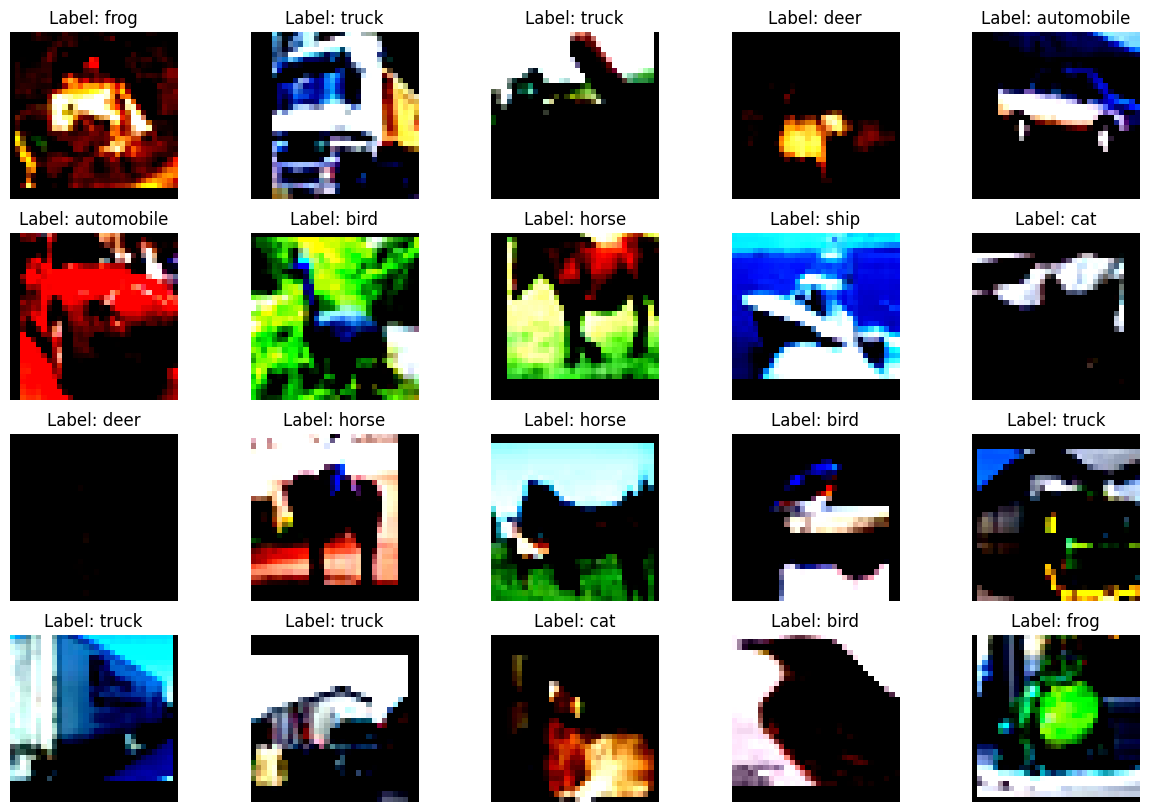

In [31]:
CIFAR10_CLASSES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

plt.figure(figsize=(15,10))

for index in range(20):
    image, label = train_dataset[index]
    image_rgb = image.permute(1, 2, 0)
    plt.subplot(4,5,index+1), plt.imshow(image_rgb), plt.title(f"Label: {CIFAR10_CLASSES[label]}")
    plt.axis("off");

#### $7)$ DataLoader 생성

In [32]:
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

#### $8)$ CNN 모델 정의

우선, CNN 구조에서 반복되는 층(Layers)을 재사용하기 위해 하나의 클래스로 만들어줍니다. CIFAR-10의 CNN 구조에서 반복되는 구간은 다음과 같습니다.

<br>
<div style="text-align: center;">
  Convolution → Batch Normalization → ReLU  → Convolution → Batch Normalization → ReLU → Max Pooling
</div>
<br>

In [33]:
class ConvBlock(nn.Module):
    """
    Convolution을 이용해 특징을 추출하고 Max Pooling을 적용하는 재사용 가능한 CNN 블록.

    기본 구조:
    Conv2d → BatchNorm2d → ReLU
    → Conv2d → BatchNorm2d → ReLU
    → MaxPool2d
    """
    
    def __init__(self, in_channels, out_channels):
        super().__init__()

         # Block을 구성할 Layer들을 순서대로 저장
        layers = [

            # 첫 번째 Convolution (특징 추출)
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False,
            ),

            # 각 출력 채널의 값 분포를 조정하여 학습 안정화
            nn.BatchNorm2d(out_channels),

            # ReLU 활성화 함수
            nn.ReLU(),

            # 두 번째 Convolution (특징 추가적으로 추출)
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False,
            ),

            # 두 번째 Convolution의 출력을 정규화
            nn.BatchNorm2d(out_channels),

            # 두 번째 활성화 함수를 적용
            nn.ReLU(),

            # Max Pooling 적용하여 다운스케일
            nn.MaxPool2d(
                kernel_size=2,
                stride=2,
            )
            
        ]

        # 리스트에 저장한 Layer들을 순서대로 실행하는 하나의 Sequential Module로 구성
        self.block = nn.Sequential(*layers)

    # 입력 x를 self.block의 Layer에 순서대로 전달
    def forward(self, x):
        return self.block(x)

In [34]:
class CIFAR10CNN(nn.Module):
    """
    CIFAR-10의 32x32 RGB 이미지를 10개 클래스로 분류하는 CNN 모델.

    전체 구조:
    ConvBlock 1
    → ConvBlock 2
    → ConvBlock 3
    → Global Average Pooling
    → Dropout
    → Linear
    """

    def __init__(self):
        super().__init__()

        # 이미지에서 특징을 추출하는 부분 (ConvBlock 1 → ConvBlock 2 → ConvBlock 3)
        self.features = nn.Sequential(

            
            ConvBlock(                 # 출력: [Batch, 64, 16, 16]
                in_channels=3,
                out_channels=64,
            ),

            
            ConvBlock(                 # 출력: [Batch, 128, 8, 8]
                in_channels=64,
                out_channels=128,
            ),

            
            ConvBlock(                 # 출력: [Batch, 256, 4, 4]
                in_channels=128,
                out_channels=256,
            ),

        )

        # 각 4×4 Feature Map의 평균을 계산하여 공간 크기를 1×1로 압축
        self.global_average_pool = (
            nn.AdaptiveAvgPool2d(
                output_size=(1, 1)     # 출력: [Batch, 256, 1, 1]
                )
        )

        # 추출된 특징을 이용해 최종 클래스를 예측
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.3),         # 출력: 256

            nn.Linear(                 # 출력: 10
                in_features=256,
                out_features=10,
            ),
        )

    # 입력 이미지: [Batch, 3, 32, 32]
    def forward(self, x):
        # 세 개의 ConvBlock을 통과하며 특징을 추출
        # 출력: [Batch, 256, 4, 4]
        x = self.features(x)

        # 각 채널의 4×4 값을 평균내어 1×1로 압축
        # 출력: [Batch, 256, 1, 1]
        x = self.global_average_pool(x)

        # Tensor를 2차원으로 펼침
        # [Batch, 256, 1, 1] → [Batch, 256]
        x = torch.flatten(x, start_dim=1)

        # 각 클래스에 대한 점수인 Logit을 계산
        # 출력: [Batch, 10]
        logits = self.classifier(x)

        return logits

#### $9)$ 모델 생성 및 GPU 지정

In [35]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU를 사용할 수 없습니다."
    )

device = torch.device("cuda")
model = CIFAR10CNN().to(device)

print("Device:", device)
print(model)

Device: cuda
CIFAR10CNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU()
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(128, eps=1e-05, moment

#### $10)$ 손실 함수 및 Optimizer 설정

In [36]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
)

#### $11)$ GPU Warm-up

In [37]:
warmup_input = torch.zeros(64, 3, 32, 32, device=device)

model.eval()

with torch.no_grad():
    for _ in range(3):
        _ = model(warmup_input)

torch.cuda.synchronize()

#### $12)$ CNN 모델 학습

앞선 MNIST 실습에서 정의한 `train_one_epoch()`와 `evaluate()` 함수를 사용하여 CIFAR-10 데이터셋을 학습해봅시다.

In [38]:
# TODO: CUDA GPU 장치에서 CIFAR-10 데이터셋을 학습과 평가
# TODO: 각 Epoch 및 전체 학습 시간을 출력

EPOCHS = 5

# 학습 기록 저장 공간 준비
train_loss_history = []
train_accuracy_history = []
test_loss_history = []
test_accuracy_history = []

# 전체 학습 시간 측정 시작
torch.cuda.synchronize()
training_start_time = time.perf_counter()

# TODO: 5번의 Epoch 동안 학습 및 평가 진행
for epoch in range(EPOCHS):
    epoch_start_time = time.perf_counter()

    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, device)
    test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

    train_loss_history.append(train_loss)
    train_accuracy_history.append(train_accuracy)
    test_loss_history.append(test_loss)
    test_accuracy_history.append(test_accuracy)

    torch.cuda.synchronize()
    epoch_time = time.perf_counter() - epoch_start_time

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: "
        f"{train_accuracy * 100:.2f}% | "
        f"Test loss: {test_loss:.4f} | "
        f"Test accuracy: "
        f"{test_accuracy * 100:.2f}% | "
        f"Time: {epoch_time:.2f}s"
    )

# TODO: 전체 학습 시간 계산 및 출력
torch.cuda.synchronize()
total_training_time = time.perf_counter() - training_start_time
print(f"Total GPU training time: {total_training_time:.2f}s")

Epoch 1/5 | Train loss: 1.3121 | Train accuracy: 52.43% | Test loss: 1.0475 | Test accuracy: 63.29% | Time: 18.89s
Epoch 2/5 | Train loss: 0.9008 | Train accuracy: 68.38% | Test loss: 0.9087 | Test accuracy: 69.62% | Time: 18.86s
Epoch 3/5 | Train loss: 0.7288 | Train accuracy: 74.95% | Test loss: 0.6235 | Test accuracy: 78.03% | Time: 19.42s
Epoch 4/5 | Train loss: 0.6310 | Train accuracy: 78.46% | Test loss: 0.6337 | Test accuracy: 78.34% | Time: 18.97s
Epoch 5/5 | Train loss: 0.5570 | Train accuracy: 80.86% | Test loss: 0.6010 | Test accuracy: 80.65% | Time: 19.14s
Total GPU training time: 95.29s


#### $14)$ 모델 저장 및 불러오기

CIFAR-10과 같이 학습에 오랜 시간이 걸리는 데이터셋은 모델을 학습시킨 뒤 저장하는 것이 중요합니다.

모델 저장:

In [39]:
save_data = {
    "model_name": "CIFAR10CNN",
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "test_accuracy": test_accuracy_history[-1],
    "epochs": EPOCHS,
    "class_names": CIFAR10_CLASSES,
    "mean": CIFAR10_MEAN,
    "std": CIFAR10_STD,
}

torch.save(
    save_data,
    "CIFAR10_CNN.pth",
)

모델 불러오기:

In [40]:
loaded_model = CIFAR10CNN()

state_dict = torch.load(
    "CIFAR10_CNN.pth", # 이 파일도 올려야됨
    map_location="cpu",
    weights_only=True,
)

loaded_model.load_state_dict(state_dict["model_state_dict"])
loaded_model.to(device)
loaded_model.eval()

CIFAR10CNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU()
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affin

모델이 제대로 불러와졌는지 확인해봅시다.

In [41]:
    # "model_name": "CIFAR10CNN",
    # "model_state_dict": model.state_dict(),
    # "optimizer_state_dict": optimizer.state_dict(),
    # "test_accuracy": test_accuracy_history[-1],
    # "epochs": EPOCHS,
    # "class_names": CIFAR10_CLASSES,
    # "mean": CIFAR10_MEAN,
    # "std": CIFAR10_STD,
print("모델 이름:", state_dict["model_name"])
print("Epoch 체크포인트:", state_dict["epochs"])
print(f"마지막 테스트 정확도: {state_dict['test_accuracy'] * 100:.2f}%")

모델 이름: CIFAR10CNN
Epoch 체크포인트: 5
마지막 테스트 정확도: 80.65%
